In [12]:
import numpy as np

X = np.array([[0, 0, 1], [0, 1, 1], [1, 0, 1], [1, 1, 1]])
D = np.array([[0] ,[0], [0], [1]])

In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [ ]:
def calc_output(W, x): # 순전파
    v = np.matmul(W, x)
    y = sigmoid(v)
    
    return y

In [ ]:
def calc_error(d, y):
    e = d - y # 정답(d)과 예측값(y)의 오차
    delta = y * (1 - y) * e

    return delta

In [ ]:
def delta_GD(W, X, D, alpha):
    for k in range(4):
        x = X[k, :].T
        d = D[k]

        y = calc_output(W, x)
        delta = calc_error(d, y)

        dW = alpha * delta * x
        W = W + dW # 틀린 만큼 가중치 수정

    return W, delta

In [13]:
W = 2 * np.random.random((1, 3)) - 1
alpha = 0.9

hist_W = []
hist_loss = []

for epoch in range(1000):
    W, delta = delta_GD(W, X, D, alpha)

    hist_loss.append(delta)
    hist_W.append(W)

    if epoch % 100 == 0:
        print(W)

[[0.35787846 0.20821955 0.6546356 ]]
[[ 2.60874579  2.57199292 -3.94612893]]
[[ 3.44694135  3.42756407 -5.23037447]]
[[ 3.94574455  3.93289617 -5.9890056 ]]
[[ 4.29693163  4.28740843 -6.52094185]]
[[ 4.56646053  4.55892953 -6.92820322]]
[[ 4.78447125  4.77825953 -7.25710214]]
[[ 4.96714543  4.96186855 -7.53239007]]
[[ 5.12413629  5.11955493 -7.76878479]]
[[ 5.26164855  5.25760406 -7.9757236 ]]


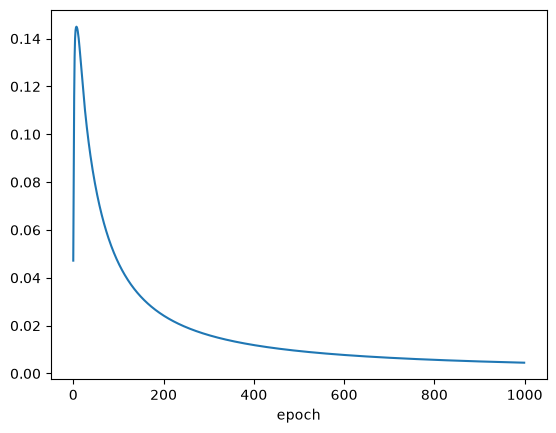

In [ ]:
import matplotlib.pyplot as plt

plt.plot(hist_loss) # 에러
plt.xlabel('epoch')
plt.show()

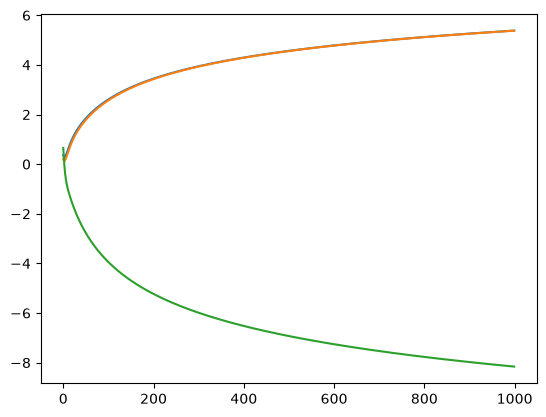

In [ ]:
plt.plot(np.array(hist_W).reshape(-1, 3)); # 가중치

In [17]:
for k in range(4):
    x = X[k, :].T
    y = calc_output(W, x)

    print(y)

[0.00028639]
[0.05848347]
[0.05868322]
[0.93111815]


#### 2층

In [18]:
def calc_output(W1, W2, x):
    v1 = np.matmul(W1, x)
    y1 = sigmoid(v1)
    v = np.matmul(W2, y1)
    y = sigmoid(v)

    return y, y1

In [19]:
def calc_delta(d, y):
    e = d - y
    delta = y * (1 - y) * e

    return delta

In [20]:
def calc_delta1(W2, delta, y1):
    e1 = np.matmul(W2.T, delta)
    delta1 = y1 * (1 - y1) * e1

    return delta1

In [21]:
def backprop_XOR(W1, W2, X, D, alpha):
    for k in range(4):
        x = X[k, :].T
        d = D[k]

        y, y1 = calc_output(W1, W2, x)
        delta = calc_delta(d, y)
        delta1 = calc_delta1(W2, delta, y1)

        dW1 = (alpha * delta1).reshape(4, 1) * x.reshape(1, 3)
        W1 = W1 + dW1

        dW2 = alpha * delta * y1
        W2 = W2 + dW2

    return W1, W2

In [22]:
X = np.array([[0, 0, 1], [0, 1, 1], [1, 0, 1], [1, 1, 1]])

D = np.array([[0], [1], [1], [0]])

W1 = 2 * np.random.random((4, 3)) - 1
W2 = 2 * np.random.random((1, 4)) - 1

In [23]:
alpha = 0.9
for epoch in range(10000):
    W1, W2 = backprop_XOR(W1, W2, X, D, alpha) # 학습

In [24]:
for k in range(4):
    x = X[k, :].T
    v1 = np.matmul(W1, x)
    y1 = sigmoid(v1)
    v = np.matmul(W2, y1)
    y = sigmoid(v)
    print(y)

[0.00871115]
[0.99089105]
[0.98970349]
[0.01273326]
